In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans

from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)



In [2]:
student_df = pd.read_csv(
    "data/processed/student_features_final.csv"
)

print(student_df.shape)

student_df.head()

(32593, 37)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,avg_daily_clicks,engagement_span_days,activity_density,click_std,daily_click_mean,click_cv,unique_sites_visited,clicks_early,clicks_mid,clicks_late,early_engagement_ratio,assessment_mean_score,assessment_median_score,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count,weighted_score_total,weighted_score_mean,avg_submission_day,first_submission_day,last_submission_day,submission_day_std
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,922.0,40.0,23.050000,258.0,0.155039,27.883411,23.050000,1.209692,55.0,528.0,182.0,212.0,0.572668,82.0,82.0,85.0,78.0,3.082207,5.0,82.4,16.48,112.4,18.0,212.0,79.103097
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1409.0,80.0,17.612500,249.0,0.321285,20.565729,17.612500,1.167678,84.0,660.0,443.0,306.0,0.468417,66.4,68.0,70.0,60.0,4.335897,5.0,65.4,13.08,114.2,22.0,212.0,78.199744
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,260.0,12.0,21.666667,22.0,0.545455,17.447758,21.666667,0.805281,22.0,260.0,0.0,0.0,1.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.00,0.0,0.0,0.0,0.000000
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2007.0,123.0,16.317073,274.0,0.448905,14.650752,16.317073,0.897879,82.0,769.0,844.0,394.0,0.383159,76.0,74.0,88.0,71.0,6.892024,5.0,76.3,15.26,112.2,17.0,213.0,80.257087
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1012.0,70.0,14.457143,257.0,0.272374,16.464882,14.457143,1.138875,66.0,597.0,249.0,166.0,0.589921,54.4,63.0,75.0,30.0,20.513410,5.0,55.0,11.00,125.6,26.0,222.0,78.811801


In [3]:
print("=" * 60)
print("DATASET SHAPE")
print("=" * 60)

print(student_df.shape)

print("\n")

print("=" * 60)
print("MISSING VALUES")
print("=" * 60)

print(
    student_df.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

DATASET SHAPE
(32593, 37)


MISSING VALUES
code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
total_clicks            0
active_days             0
avg_daily_clicks        0
engagement_span_days    0
activity_density        0
click_std               0
daily_click_mean        0
click_cv                0
dtype: int64


In [4]:
cluster_features = [

    # Engagement

    "total_clicks",
    "active_days",
    "avg_daily_clicks",
    "engagement_span_days",

    "activity_density",

    "click_std",
    "daily_click_mean",
    "click_cv",

    "unique_sites_visited",

    # Temporal Behavior

    "clicks_early",
    "clicks_mid",
    "clicks_late",

    "early_engagement_ratio",

    # Assessment Performance

    "assessment_mean_score",
    "assessment_median_score",
    "assessment_max_score",
    "assessment_min_score",

    "assessment_std_score",
    "assessment_count",

    # Weighted Performance

    "weighted_score_total",
    "weighted_score_mean",

    # Submission Behavior

    "avg_submission_day",
    "first_submission_day",
    "last_submission_day",

    "submission_day_std"

]

X_cluster = student_df[
    cluster_features
].copy()

print(X_cluster.shape)

(32593, 25)


In [5]:
missing_summary = (
    X_cluster
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[missing_summary > 0]

Series([], dtype: int64)

In [6]:
X_cluster = X_cluster.replace(
    [np.inf, -np.inf],
    np.nan
)

X_cluster = X_cluster.fillna(
    X_cluster.median()
)

In [7]:
print("Missing Values Remaining")

print(
    X_cluster
    .isnull()
    .sum()
    .sum()
)

print("\n")

print("Infinite Values Remaining")

print(
    np.isinf(X_cluster).sum().sum()
)

Missing Values Remaining
0


Infinite Values Remaining
0


In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

print(X_scaled.shape)

(32593, 25)


In [9]:
scaled_df = pd.DataFrame(
    X_scaled,
    columns=cluster_features
)

scaled_df.describe().T[
    ["mean", "std"]
].head()

,mean,std
total_clicks,-5.580920e-17,1.000015
active_days,-5.232113e-17,1.000015
avg_daily_clicks,-2.092845e-16,1.000015
engagement_span_days,-8.720188e-18,1.000015
activity_density,-6.278536e-17,1.000015


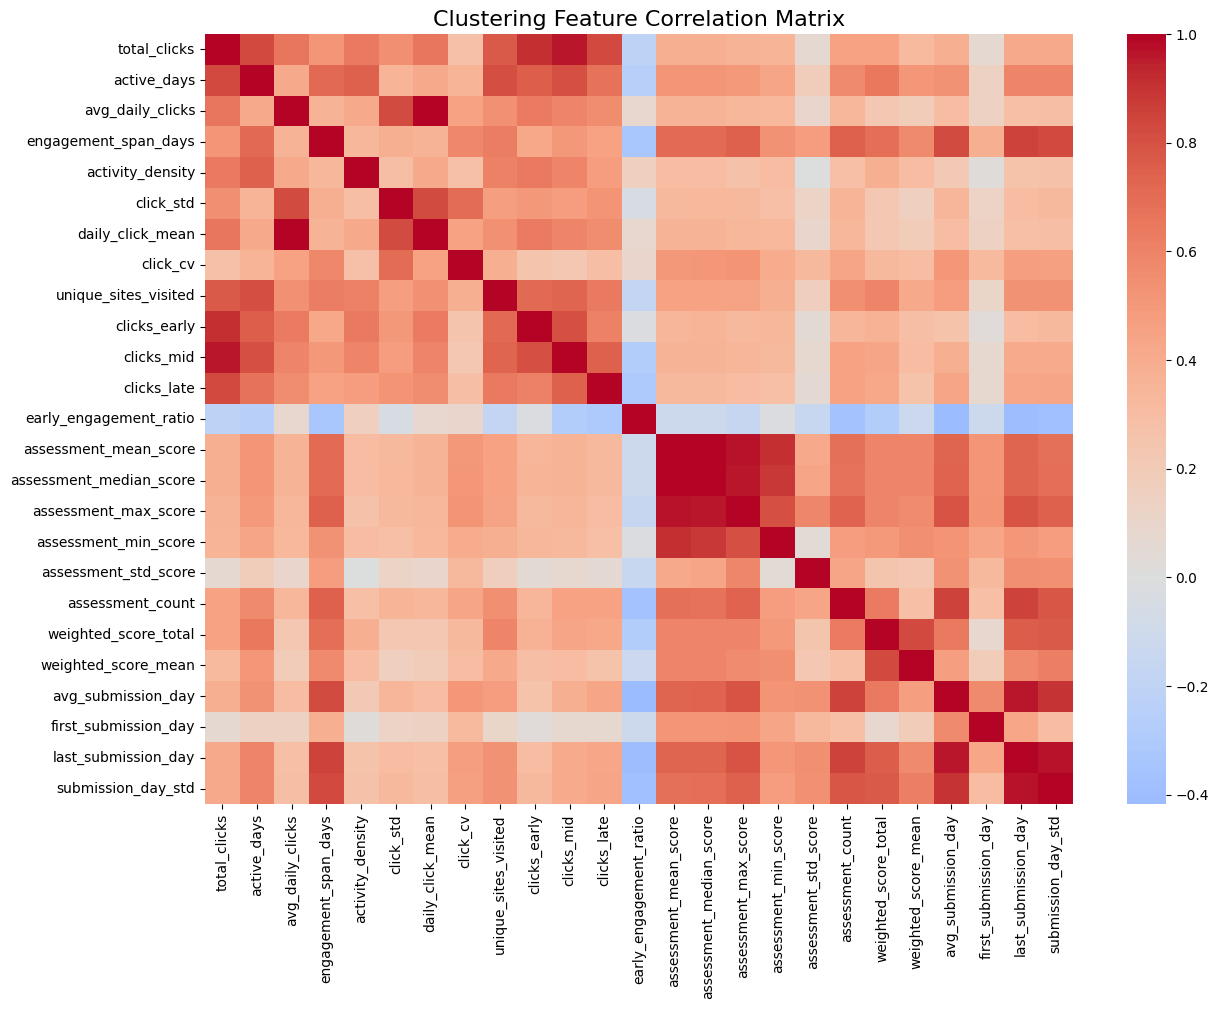

In [10]:
plt.figure(figsize=(14,10))

sns.heatmap(
    X_cluster.corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Clustering Feature Correlation Matrix",
    fontsize=16
)

plt.show()

In [11]:
pca = PCA()

pca.fit(X_scaled)

explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(explained_variance)

[0.49030774 0.64582168 0.72796319 0.79085256 0.83283292 0.86836918
 0.8941642  0.91862161 0.9365818  0.95038678 0.96198927 0.97230999
 0.98012761 0.98623963 0.99144998 0.99395212 0.99596113 0.99731545
 0.99852567 0.99931496 0.99971144 0.99994484 1.         1.
 1.        ]


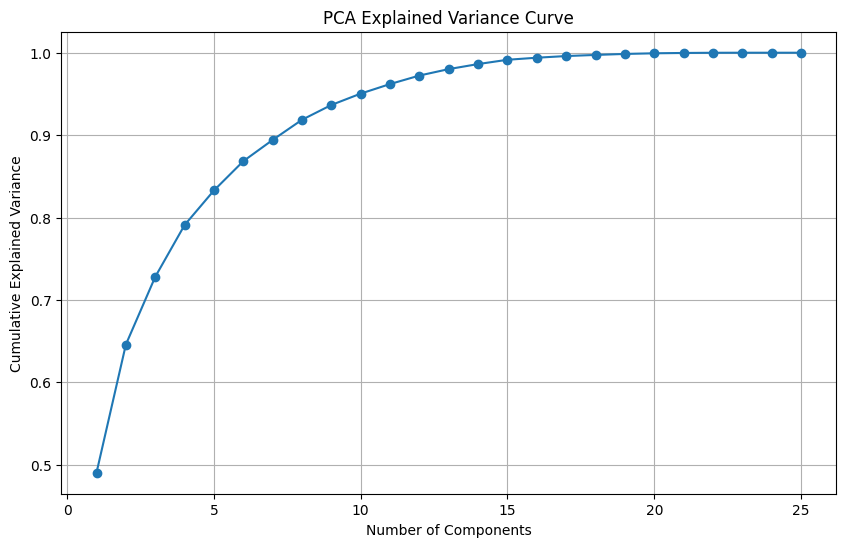

In [12]:
plt.figure(figsize=(10,6))

plt.plot(
    range(
        1,
        len(explained_variance)+1
    ),
    explained_variance,
    marker="o"
)

plt.xlabel("Number of Components")

plt.ylabel(
    "Cumulative Explained Variance"
)

plt.title(
    "PCA Explained Variance Curve"
)

plt.grid(True)

plt.show()

In [13]:
inertia_values = []

k_range = range(2, 11)

for k in k_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    kmeans.fit(X_scaled)

    inertia_values.append(
        kmeans.inertia_
    )

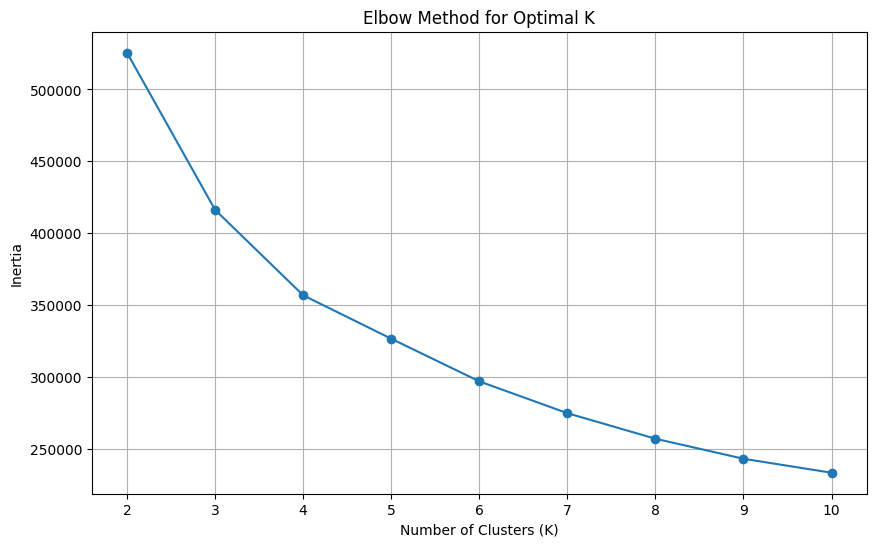

In [14]:
plt.figure(figsize=(10,6))

plt.plot(
    k_range,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title(
    "Elbow Method for Optimal K"
)

plt.grid(True)

plt.show()

In [15]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(
        X_scaled
    )

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"K={k} -> Silhouette={score:.4f}"
    )

K=2 -> Silhouette=0.3453
K=3 -> Silhouette=0.2987
K=4 -> Silhouette=0.2751
K=5 -> Silhouette=0.2941
K=6 -> Silhouette=0.2698
K=7 -> Silhouette=0.2682
K=8 -> Silhouette=0.2765
K=9 -> Silhouette=0.2758
K=10 -> Silhouette=0.2803


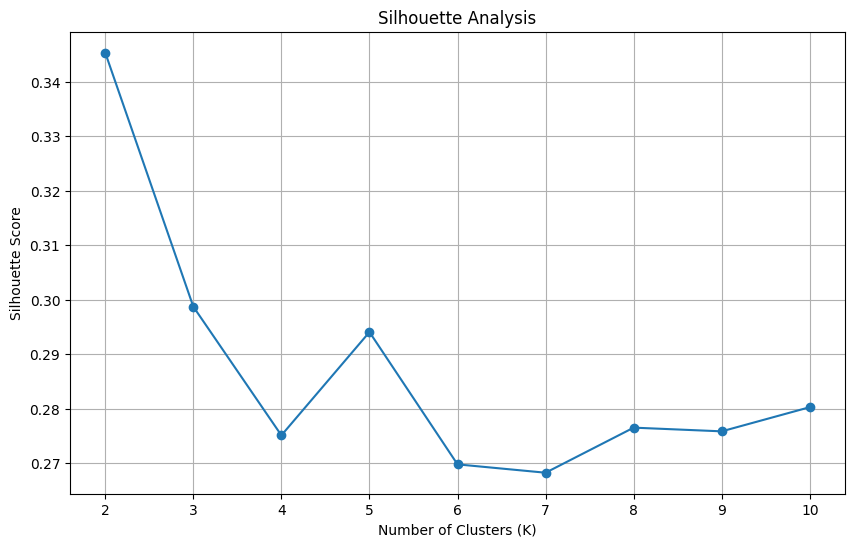

In [16]:
plt.figure(figsize=(10,6))

plt.plot(
    range(2,11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title(
    "Silhouette Analysis"
)

plt.grid(True)

plt.show()

In [17]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans.fit_predict(
    X_scaled
)

cluster_labels

array([4, 4, 0, ..., 4, 2, 4], shape=(32593,), dtype=int32)

In [18]:
student_df["cluster"] = cluster_labels

student_df["cluster"].value_counts()

cluster
4    13574
2     6391
3     5462
0     4273
1     2893
Name: count, dtype: int64

In [19]:
student_df["cluster"].value_counts()

cluster
4    13574
2     6391
3     5462
0     4273
1     2893
Name: count, dtype: int64

In [20]:
cluster_profile = student_df.groupby("cluster")[
    [
        "total_clicks",
        "active_days",
        "avg_daily_clicks",
        "engagement_span_days",
        "activity_density",
        "unique_sites_visited",
        "clicks_early",
        "clicks_mid",
        "clicks_late",
        "assessment_mean_score",
        "assessment_count",
        "weighted_score_mean",
        "avg_submission_day"
    ]
].mean()

cluster_profile.round(2)

,total_clicks,active_days,avg_daily_clicks,engagement_span_days,activity_density,unique_sites_visited,clicks_early,clicks_mid,clicks_late,assessment_mean_score,assessment_count,weighted_score_mean,avg_submission_day
cluster,,,,,,,,,,,,,
0,375.76,19.71,16.14,66.18,inf,30.44,232.13,103.67,39.96,1.39,0.11,0.08,2.49
1,0.35,0.06,0.08,1.00,inf,0.10,0.04,0.28,0.03,0.36,0.02,0.03,0.12
2,581.03,31.37,17.67,116.08,inf,47.98,447.44,118.92,14.67,67.37,2.42,5.88,40.76
3,4796.50,151.55,32.70,262.44,0.57,174.00,1722.39,2018.38,1055.74,79.62,9.56,10.78,119.66
4,1116.60,70.53,16.06,243.67,inf,73.76,424.55,464.21,227.84,74.15,7.77,10.77,118.76


In [21]:
cluster_sizes = (
    student_df["cluster"]
    .value_counts()
    .sort_index()
)

cluster_sizes

cluster
0     4273
1     2893
2     6391
3     5462
4    13574
Name: count, dtype: int64

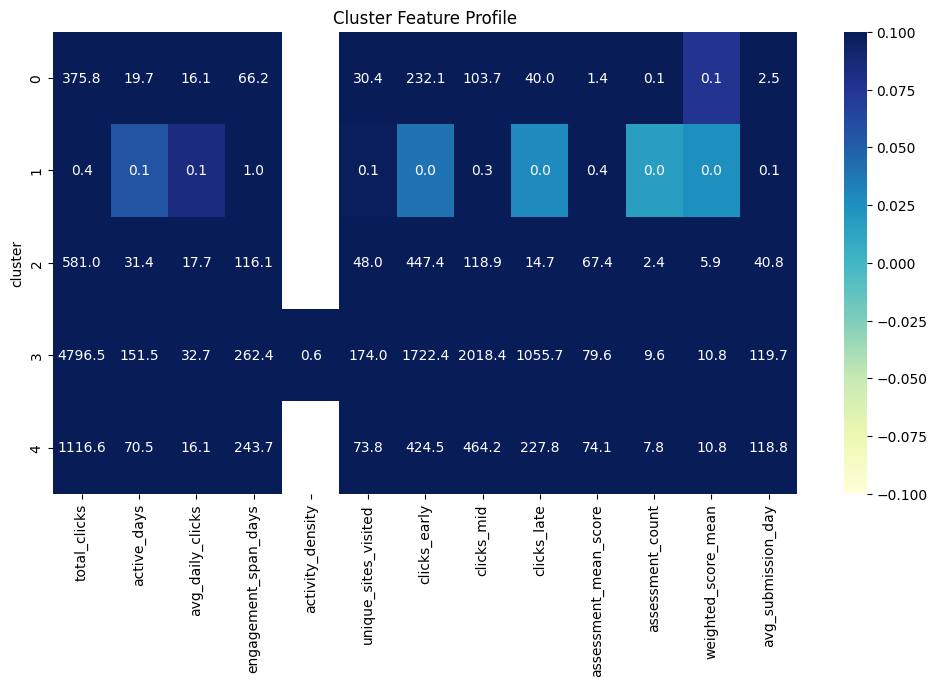

In [22]:
plt.figure(figsize=(12,6))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title(
    "Cluster Feature Profile"
)

plt.show()

In [23]:
cluster_outcomes = pd.crosstab(
    student_df["cluster"],
    student_df["final_result"],
    normalize="index"
) * 100

cluster_outcomes.round(2)

final_result,Distinction,Fail,Pass,Withdrawn
cluster,,,,
0,0.00,25.16,0.05,74.80
1,0.00,12.20,0.03,87.76
2,0.02,45.64,0.20,54.14
3,23.32,7.74,62.85,6.08
4,12.88,16.83,65.65,4.63


PCA 2D Projection

In [24]:
from sklearn.decomposition import PCA

pca_2d = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca_2d.fit_transform(X_scaled)

print(X_pca.shape)

(32593, 2)


In [25]:
pca_df = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "cluster": student_df["cluster"]
    }
)

pca_df.head()

,PC1,PC2,cluster
0,1.500325,-1.298115,4
1,1.293920,-0.717144,4
2,-4.621406,2.666004,0
3,2.075913,-0.639485,4
4,0.810136,-1.492273,4


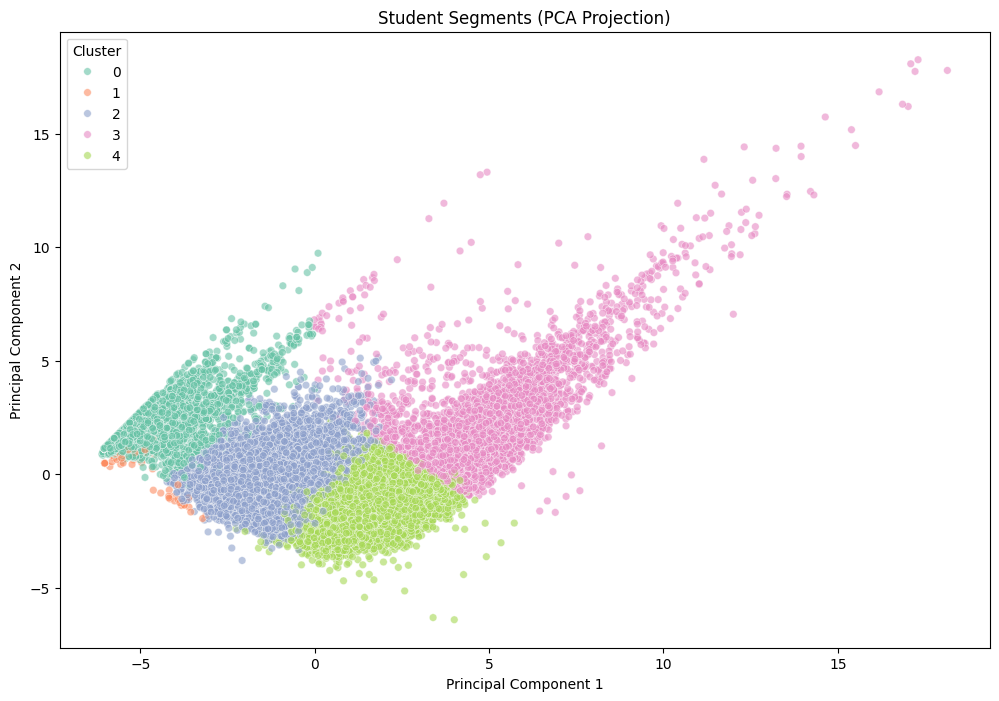

In [26]:
plt.figure(figsize=(12,8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    alpha=0.6,
    s=30
)

plt.title(
    "Student Segments (PCA Projection)"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")

plt.show()

In [27]:
print(
    "PC1 Variance:",
    round(
        pca_2d.explained_variance_ratio_[0] * 100,
        2
    ),
    "%"
)

print(
    "PC2 Variance:",
    round(
        pca_2d.explained_variance_ratio_[1] * 100,
        2
    ),
    "%"
)

print(
    "Total Variance:",
    round(
        pca_2d.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

PC1 Variance: 49.03 %
PC2 Variance: 15.55 %
Total Variance: 64.58 %


In [28]:
cluster_names = {
    0: "Struggling Learners",
    1: "Early Dropouts",
    2: "Academically At-Risk Students",
    3: "High Achievers",
    4: "Consistent Learners"
}

student_df["cluster_name"] = (
    student_df["cluster"]
    .map(cluster_names)
)

student_df[
    ["cluster", "cluster_name"]
].head()

,cluster,cluster_name
0,4,Consistent Learners
1,4,Consistent Learners
2,0,Struggling Learners
3,4,Consistent Learners
4,4,Consistent Learners


In [29]:
student_df[
    "cluster_name"
].value_counts()

cluster_name
Consistent Learners              13574
Academically At-Risk Students     6391
High Achievers                    5462
Struggling Learners               4273
Early Dropouts                    2893
Name: count, dtype: int64

In [30]:
cluster_statistics = (
    student_df
    .groupby("cluster_name")
    .agg(
        student_count=("id_student", "count"),
        avg_clicks=("total_clicks", "mean"),
        avg_active_days=("active_days", "mean"),
        avg_score=("assessment_mean_score", "mean"),
        avg_sites=("unique_sites_visited", "mean"),
        avg_submission_day=("avg_submission_day", "mean")
    )
)

cluster_statistics = (
    cluster_statistics
    .sort_values(
        by="student_count",
        ascending=False
    )
)

cluster_statistics.round(2)

,student_count,avg_clicks,avg_active_days,avg_score,avg_sites,avg_submission_day
cluster_name,,,,,,
Consistent Learners,13574,1116.60,70.53,74.15,73.76,118.76
Academically At-Risk Students,6391,581.03,31.37,67.37,47.98,40.76
High Achievers,5462,4796.50,151.55,79.62,174.00,119.66
Struggling Learners,4273,375.76,19.71,1.39,30.44,2.49
Early Dropouts,2893,0.35,0.06,0.36,0.10,0.12


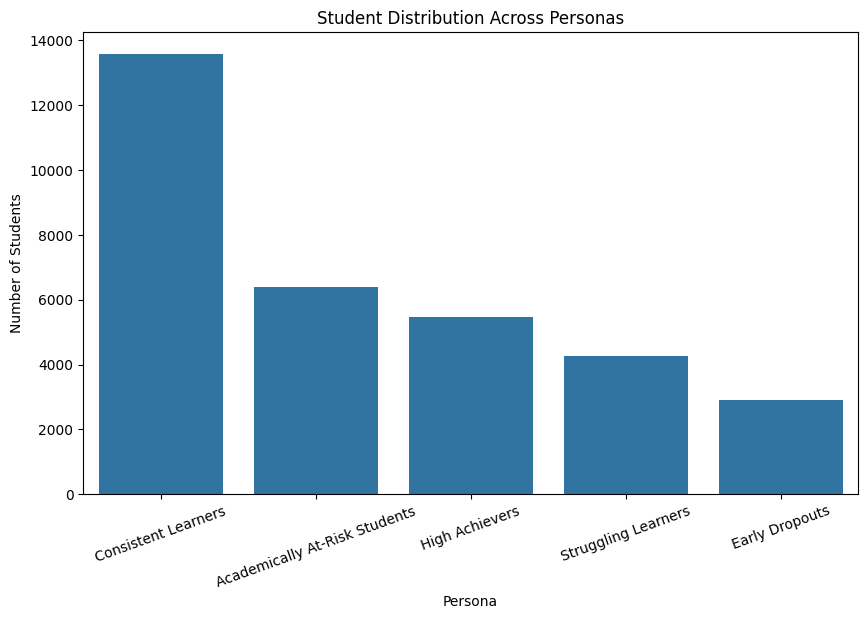

In [31]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=student_df,
    x="cluster_name",
    order=student_df["cluster_name"]
    .value_counts()
    .index
)

plt.xticks(
    rotation=20
)

plt.title(
    "Student Distribution Across Personas"
)

plt.xlabel("Persona")
plt.ylabel("Number of Students")

plt.show()

In [32]:
outcome_persona = pd.crosstab(
    student_df["cluster_name"],
    student_df["final_result"],
    normalize="index"
) * 100

outcome_persona.round(2)

final_result,Distinction,Fail,Pass,Withdrawn
cluster_name,,,,
Academically At-Risk Students,0.02,45.64,0.20,54.14
Consistent Learners,12.88,16.83,65.65,4.63
Early Dropouts,0.00,12.20,0.03,87.76
High Achievers,23.32,7.74,62.85,6.08
Struggling Learners,0.00,25.16,0.05,74.80


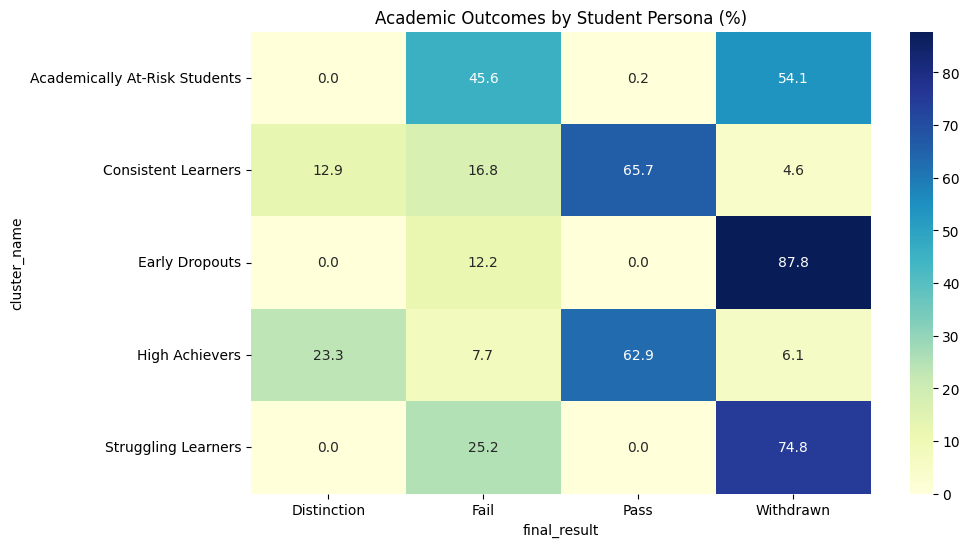

In [33]:
plt.figure(figsize=(10,6))

sns.heatmap(
    outcome_persona,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title(
    "Academic Outcomes by Student Persona (%)"
)

plt.show()

In [34]:
student_df.to_csv(
    "data/processed/student_clusters.csv",
    index=False
)

print(
    "student_clusters.csv saved successfully"
)

student_clusters.csv saved successfully


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

In [36]:
cluster_features = [

    "total_clicks",
    "active_days",
    "avg_daily_clicks",
    "engagement_span_days",
    "activity_density",
    "click_std",
    "daily_click_mean",
    "click_cv",
    "unique_sites_visited",

    "clicks_early",
    "clicks_mid",
    "clicks_late",

    "early_engagement_ratio",

    "assessment_mean_score",
    "assessment_median_score",
    "assessment_max_score",
    "assessment_min_score",
    "assessment_std_score",
    "assessment_count",

    "weighted_score_total",
    "weighted_score_mean",

    "avg_submission_day",
    "first_submission_day",
    "last_submission_day",
    "submission_day_std"
]

X = student_df[cluster_features]

y = student_df["cluster"]

In [40]:
import numpy as np

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(26074, 25)
(6519, 25)


In [42]:
for col in X.columns:

    if np.isinf(X[col]).sum() > 0:

        print(
            col,
            np.isinf(X[col]).sum()
        )

In [43]:
cluster_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

cluster_rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [44]:
cluster_pred = cluster_rf.predict(
    X_test
)

In [45]:
cluster_accuracy = accuracy_score(
    y_test,
    cluster_pred
)

print(
    "Cluster Prediction Accuracy:",
    round(cluster_accuracy,4)
)

Cluster Prediction Accuracy: 0.9816


In [46]:
print(
    classification_report(
        y_test,
        cluster_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       855
           1       1.00      0.99      1.00       579
           2       0.97      0.98      0.98      1278
           3       0.96      0.98      0.97      1092
           4       0.99      0.98      0.98      2715

    accuracy                           0.98      6519
   macro avg       0.98      0.98      0.98      6519
weighted avg       0.98      0.98      0.98      6519



In [47]:
cm = confusion_matrix(
    y_test,
    cluster_pred
)

cm

array([[ 847,    0,    6,    2,    0],
       [   3,  576,    0,    0,    0],
       [   5,    2, 1249,    5,   17],
       [   1,    0,    2, 1071,   18],
       [   0,    0,   25,   34, 2656]])

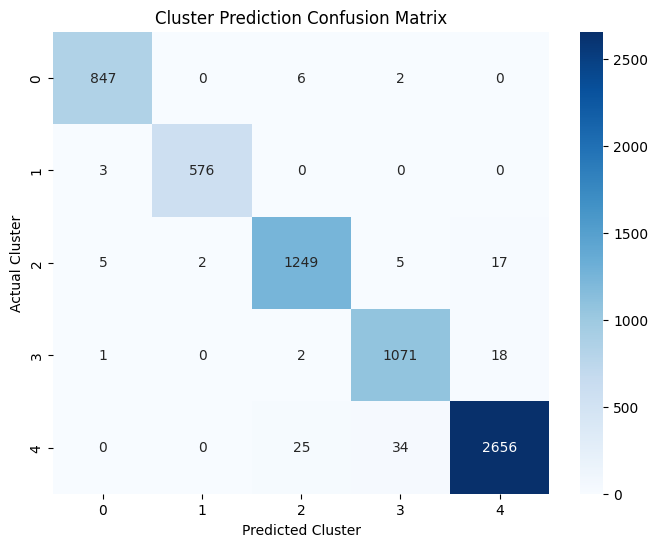

In [48]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Cluster")

plt.title(
    "Cluster Prediction Confusion Matrix"
)

plt.show()


In [49]:
importance_df = pd.DataFrame({

    "feature": cluster_features,

    "importance":
    cluster_rf.feature_importances_

})

In [50]:
importance_df = (
    importance_df
    .sort_values(
        by="importance",
        ascending=False
    )
)

importance_df.head(15)

,feature,importance
0,total_clicks,0.127263
23,last_submission_day,0.114587
21,avg_submission_day,0.064361
9,clicks_early,0.061681
24,submission_day_std,0.061545
15,assessment_max_score,0.058450
11,clicks_late,0.058225
18,assessment_count,0.058014
10,clicks_mid,0.045470
13,assessment_mean_score,0.041169


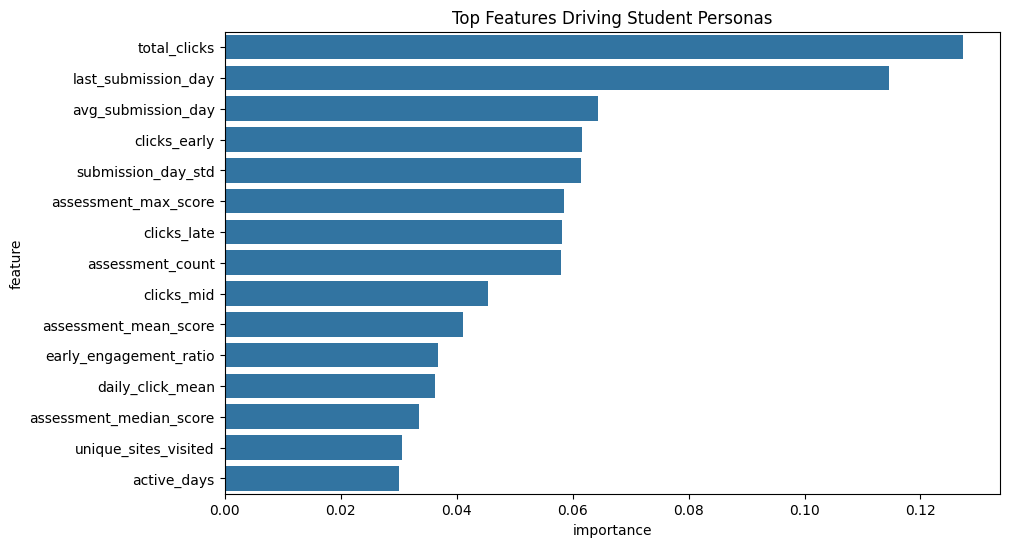

In [51]:
top_features = importance_df.head(15)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title(
    "Top Features Driving Student Personas"
)

plt.show()

In [52]:
import joblib

joblib.dump(
    cluster_rf,
    "models/persona_predictor.pkl"
)

print(
    "persona_predictor.pkl saved"
)

persona_predictor.pkl saved


In [53]:
importance_df.to_csv(
    "data/processed/persona_feature_importance.csv",
    index=False
)

print(
    "persona_feature_importance.csv saved"
)

persona_feature_importance.csv saved


In [54]:
risk_mapping = {
    "High Achievers": "Very Low",
    "Consistent Learners": "Low",
    "Academically At-Risk Students": "High",
    "Struggling Learners": "High",
    "Early Dropouts": "Critical"
}

student_df["risk_level"] = student_df["cluster_name"].map(
    risk_mapping
)

student_df["risk_score"] = student_df["risk_level"].map(
    {
        "Very Low":1,
        "Low":2,
        "High":4,
        "Critical":5
    }
)

student_df[
    ["cluster_name","risk_level","risk_score"]
].head()

,cluster_name,risk_level,risk_score
0,Consistent Learners,Low,2
1,Consistent Learners,Low,2
2,Struggling Learners,High,4
3,Consistent Learners,Low,2
4,Consistent Learners,Low,2


In [55]:
student_df["low_engagement_flag"] = (
    student_df["total_clicks"]
    <
    student_df["total_clicks"].quantile(0.25)
).astype(int)

student_df["low_activity_flag"] = (
    student_df["active_days"]
    <
    student_df["active_days"].quantile(0.25)
).astype(int)

student_df["low_assessment_flag"] = (
    student_df["assessment_count"]
    <
    student_df["assessment_count"].quantile(0.25)
).astype(int)

student_df[
    [
        "low_engagement_flag",
        "low_activity_flag",
        "low_assessment_flag"
    ]
].sum()

low_engagement_flag    8141
low_activity_flag      7921
low_assessment_flag    6773
dtype: int64

In [56]:
student_df["poor_score_flag"] = (
    student_df["assessment_mean_score"]
    <
    student_df["assessment_mean_score"].quantile(0.25)
).astype(int)

student_df["late_submission_flag"] = (
    student_df["avg_submission_day"]
    >
    student_df["avg_submission_day"].quantile(0.75)
).astype(int)

student_df[
    [
        "poor_score_flag",
        "late_submission_flag"
    ]
].sum()

poor_score_flag         8148
late_submission_flag    8144
dtype: int64

In [57]:
student_df["behavior_risk_index"] = (
      student_df["low_engagement_flag"]
    + student_df["low_activity_flag"]
    + student_df["low_assessment_flag"]
    + student_df["poor_score_flag"]
    + student_df["late_submission_flag"]
)

student_df["behavior_risk_index"].describe()

count    32593.000000
mean         1.200472
std          1.436580
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: behavior_risk_index, dtype: float64

In [58]:
def intervention_category(row):

    if row["risk_level"] == "Critical":
        return "Immediate Intervention"

    if row["behavior_risk_index"] >= 4:
        return "Intensive Academic Support"

    if row["behavior_risk_index"] >= 2:
        return "Moderate Support"

    return "Performance Enhancement"


student_df["intervention_category"] = student_df.apply(
    intervention_category,
    axis=1
)

student_df[
    "intervention_category"
].value_counts()

intervention_category
Performance Enhancement       23616
Moderate Support               3544
Immediate Intervention         2893
Intensive Academic Support     2540
Name: count, dtype: int64

In [59]:
recommendation_map = {

    "High Achievers":[
        "Research Opportunities",
        "Advanced Coursework",
        "Leadership Programs",
        "Peer Mentorship"
    ],

    "Consistent Learners":[
        "Maintain Learning Routine",
        "Skill Development Workshops",
        "Career Preparation Programs",
        "Advanced Learning Resources"
    ],

    "Academically At-Risk Students":[
        "Targeted Tutoring",
        "Weekly Faculty Mentoring",
        "Practice Assessments",
        "Progress Monitoring"
    ],

    "Struggling Learners":[
        "Study Plan Development",
        "Academic Counseling",
        "Assessment Support Sessions",
        "Weekly Review Meetings"
    ],

    "Early Dropouts":[
        "Immediate Faculty Outreach",
        "LMS Re-Onboarding",
        "Mentor Assignment",
        "Weekly Engagement Tracking"
    ]
}

In [60]:
student_df["recommendation_1"] = (
    student_df["cluster_name"]
    .map(lambda x: recommendation_map[x][0])
)

student_df["recommendation_2"] = (
    student_df["cluster_name"]
    .map(lambda x: recommendation_map[x][1])
)

student_df["recommendation_3"] = (
    student_df["cluster_name"]
    .map(lambda x: recommendation_map[x][2])
)

student_df["recommendation_4"] = (
    student_df["cluster_name"]
    .map(lambda x: recommendation_map[x][3])
)

In [61]:
intervention_summary = (
    student_df
    .groupby(
        ["cluster_name","risk_level"]
    )
    .agg(
        student_count=("id_student","count"),
        avg_clicks=("total_clicks","mean"),
        avg_score=("assessment_mean_score","mean"),
        avg_risk_index=("behavior_risk_index","mean")
    )
    .round(2)
    .reset_index()
)

intervention_summary

,cluster_name,risk_level,student_count,avg_clicks,avg_score,avg_risk_index
0,Academically At-Risk Students,High,6391,581.03,67.37,0.63
1,Consistent Learners,Low,13574,1116.60,74.15,0.50
2,Early Dropouts,Critical,2893,0.35,0.36,3.99
3,High Achievers,Very Low,5462,4796.50,79.62,0.52
4,Struggling Learners,High,4273,375.76,1.39,3.26


In [62]:
high_risk_students = student_df[
    student_df["risk_level"].isin(
        ["High","Critical"]
    )
].copy()

print(
    "High Risk Students:",
    high_risk_students.shape
)

high_risk_students.head()

High Risk Students: (13557, 52)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,avg_daily_clicks,engagement_span_days,activity_density,click_std,daily_click_mean,click_cv,unique_sites_visited,clicks_early,clicks_mid,clicks_late,early_engagement_ratio,assessment_mean_score,assessment_median_score,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count,weighted_score_total,weighted_score_mean,avg_submission_day,first_submission_day,last_submission_day,submission_day_std,cluster,cluster_name,risk_level,risk_score,low_engagement_flag,low_activity_flag,low_assessment_flag,poor_score_flag,late_submission_flag,behavior_risk_index,intervention_category,recommendation_1,recommendation_2,recommendation_3,recommendation_4
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,260.0,12.0,21.666667,22.0,0.545455,17.447758,21.666667,0.805281,22.0,260.0,0.0,0.0,1.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0,Struggling Learners,High,4,0,1,1,1,0,3,Moderate Support,Study Plan Development,Academic Counseling,Assessment Support Sessions,Weekly Review Meetings
15,AAA,2013J,65002,F,East Anglian Region,A Level or Equivalent,70-80%,0-35,0,60,N,Withdrawn,176.0,13.0,13.538462,225.0,0.057778,14.711761,13.538462,1.086664,26.0,173.0,1.0,2.0,0.982955,67.0,67.0,68.0,66.0,1.414214,2.0,20.2,10.100000,34.000000,17.0,51.0,24.041631,2,Academically At-Risk Students,High,4,1,1,0,0,0,2,Moderate Support,Targeted Tutoring,Weekly Faculty Mentoring,Practice Assessments,Progress Monitoring
22,AAA,2013J,94961,M,South Region,Lower Than A Level,70-80%,35-55,0,60,N,Withdrawn,1218.0,93.0,13.096774,289.0,0.321799,16.178397,13.096774,1.235296,69.0,854.0,254.0,110.0,0.701149,74.0,74.0,74.0,74.0,0.000000,1.0,7.4,7.400000,17.000000,17.0,17.0,0.000000,2,Academically At-Risk Students,High,4,0,0,0,0,0,0,Performance Enhancement,Targeted Tutoring,Weekly Faculty Mentoring,Practice Assessments,Progress Monitoring
29,AAA,2013J,106247,M,South Region,HE Qualification,80-90%,35-55,0,60,N,Withdrawn,449.0,33.0,13.606061,138.0,0.239130,19.176710,13.606061,1.409424,43.0,339.0,110.0,0.0,0.755011,60.0,66.0,67.0,47.0,11.269428,3.0,29.3,9.766667,70.333333,32.0,115.0,41.860881,2,Academically At-Risk Students,High,4,0,0,0,0,0,0,Performance Enhancement,Targeted Tutoring,Weekly Faculty Mentoring,Practice Assessments,Progress Monitoring
44,AAA,2013J,135335,F,East Anglian Region,Lower Than A Level,20-30%,0-35,0,180,N,Withdrawn,73.0,14.0,5.214286,48.0,0.291667,5.294098,5.214286,1.015306,12.0,73.0,0.0,0.0,1.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0,Struggling Learners,High,4,1,0,1,1,0,3,Moderate Support,Study Plan Development,Academic Counseling,Assessment Support Sessions,Weekly Review Meetings


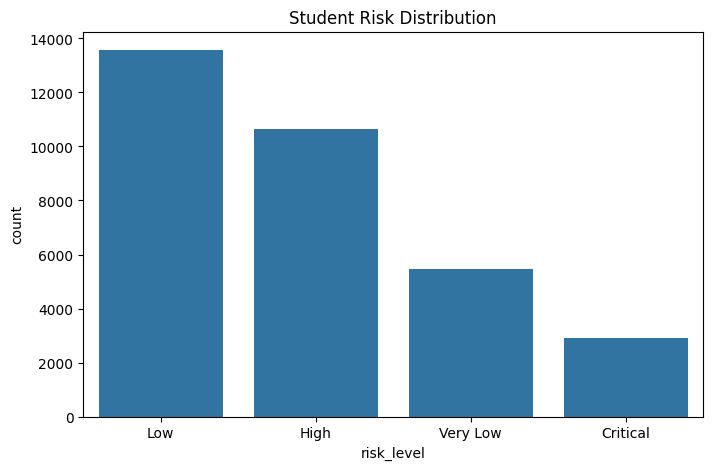

In [63]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=student_df,
    x="risk_level"
)

plt.title(
    "Student Risk Distribution"
)

plt.show()

In [64]:
student_df.to_csv(
    "data/processed/student_interventions.csv",
    index=False
)

intervention_summary.to_csv(
    "data/processed/intervention_summary.csv",
    index=False
)

high_risk_students.to_csv(
    "data/processed/high_risk_students.csv",
    index=False
)

print("All intervention files saved successfully.")

All intervention files saved successfully.


In [65]:
student_df.to_csv(
    "data/processed/student_clustered.csv",
    index=False
)

In [66]:
import joblib

joblib.dump(
    kmeans,
    "models/final_kmeans.pkl"
)

print("KMeans saved")

KMeans saved
